# Value at Risk of a Market-Cap-Weighted Stock Portfolio
## MSFT, AAPL and GOOGL — empirical and normal-EWMA VaR under three loss operators

A \$1,000,000 portfolio holds Microsoft, Apple and Google in proportion to their
market capitalisations on 05/22/2026. Using two years of daily closing prices from
Yahoo Finance, this notebook estimates the one-day 95% Value at Risk two ways —
from the **empirical distribution** of the 500 historical log returns, and from a
**normal model** whose mean vector and covariance matrix are EWMA estimates — each
under the full, linearized and quadratic loss operators, and then compares the six
numbers.

**Notation.** $V_t=\sum_i\lambda^{(i)}S^{(i)}_t$ is the portfolio value,
$\omega_i=\lambda^{(i)}S^{(i)}_t/V_t$ the market weights, and $x\in\mathbb R^3$ the
vector of one-day log returns. With $V_t=V$ fixed at \$1,000,000 the three loss
operators are

$$\ell_{[t]}(x)=-V\sum_{i=1}^3\omega_i\bigl(e^{x_i}-1\bigr),\qquad
\ell^{\mathrm{lin}}_{[t]}(x)=-V\sum_{i=1}^3\omega_i\,x_i,\qquad
\ell^{\mathrm{quad}}_{[t]}(x)=-V\sum_{i=1}^3\omega_i\Bigl(x_i+\tfrac12x_i^2\Bigr).$$

For $n$ loss observations sorted as $\ell_{(1)}\le\dots\le\ell_{(n)}$ the VaR of the
empirical distribution is $\widehat{\mathrm{VaR}}_\alpha=\ell_{(\lceil n\alpha\rceil)}$,
and if $X\sim N(\mu,\Sigma)$ the linearized loss is normal, so
$\mathrm{VaR}_\alpha(L^{\mathrm{lin}})=-V\omega^{\top}\mu+V\sqrt{\omega^{\top}\Sigma\,\omega}\;\Phi^{-1}(\alpha)$.

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.5.3
pandas      3.0.5
scipy       1.18.1
matplotlib  3.11.2


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| — | tickers | MSFT, AAPL, GOOGL |
| — | sample period (closing prices) | 05/23/2024 – 05/22/2026 |
| $\mathrm{cap}_i$ | market capitalisation on 05/22/2026, \$ trillion | 3.109, 4.536, 4.64 |
| $V$ | portfolio value | \$1,000,000 |
| $\alpha$ | VaR confidence level | 0.95 |
| $\lambda,\ \theta$ | EWMA decay for the mean and the covariance | 0.97, 0.97 |
| $\mu_0,\ \Sigma_0$ | EWMA starting values | $0$, $0$ |
| $N$ | Monte-Carlo samples | 100,000 |

The seed is fixed, so re-running the notebook reproduces every number exactly.

In [2]:
TICKERS   = ["MSFT", "AAPL", "GOOGL"]
FIRST_DAY = "2024-05-23"
LAST_DAY  = "2026-05-22"
CAP_TRN   = np.array([3.109, 4.536, 4.64])   # $ trillion, as of 05/22/2026, same order as TICKERS
V_PORT    = 1_000_000.0
ALPHA     = 0.95
LAM       = 0.97      # EWMA decay for the mean      (lambda)
THETA     = 0.97      # EWMA decay for the covariance (theta)
N_MC      = 100_000
SEED      = 731

DATA_FILE = Path("stock_prices.csv")
FIG1 = Path("var_est_loss_distributions.png")
FIG2 = Path("var_est_ewma_var_path.png")

Z_ALPHA = norm.ppf(ALPHA)
usd = lambda v: ("-" if v < 0 else "") + r"\$" + f"{abs(v):,.0f}"   # dollar amount, safe in matplotlib text

# colour-blind-safe, print-friendly
C_HIST, C_NORM, C_QUAD = "#2a78d6", "#eb6834", "#4a3aa7"
C_INK, C_MUTE = "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"alpha = {ALPHA},  Phi^-1(alpha) = {Z_ALPHA:.6f},  N = {N_MC:,},  seed = {SEED}")

alpha = 0.95,  Phi^-1(alpha) = 1.644854,  N = 100,000,  seed = 731


---
## 3. Data — Question 1

Daily **closing** prices from Yahoo Finance, not adjusted for dividends
(`auto_adjust=False`, column `Close`). None of the three stocks split during the
sample, so the raw closes have no artificial jumps. Only trading days appear;
weekends and exchange holidays are never filled in. The prices are cached in
`stock_prices.csv` after the first download, so every later run is offline and
reproducible.

### Pseudocode — data acquisition

```
INPUT : tickers, first day d0, last day d1 (inclusive), cache file F
OUTPUT: one table, a row per trading day, a column of closing prices per ticker

 1  if F exists: read the table from F                  (no network access)
 2  else
 3        for each ticker: request the daily raw closes on [d0, d1] from Yahoo Finance
 4              ('end' is exclusive there, so ask for d1 + 1 day)
 5              if nothing comes back: stop and report it - never invent prices
 6        keep the trading days common to all tickers; sort by date; save to F
 7  check: first date = d0, last date = d1, no missing values, no repeated dates
 8  return the table
```

In [3]:
def download_closes(tickers, first, last):
    """Raw daily closes from Yahoo Finance on [first, last] (only used when the cache is missing)."""
    import yfinance as yf
    end = (pd.Timestamp(last) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    cols = []
    for t in tickers:
        df = yf.download(t, start=first, end=end, interval="1d", auto_adjust=False,
                         actions=False, progress=False, threads=False)
        if df is None or df.empty:
            raise RuntimeError(f"Yahoo Finance returned no data for {t}")
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        s = df["Close"].astype(float)
        s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
        cols.append(s.rename(t))
    table = pd.concat(cols, axis=1, join="inner").sort_index()
    table.index.name = "Date"
    return table.loc[first:last]


if DATA_FILE.exists():
    prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)
    print(f"read cached prices from {DATA_FILE}")
else:
    prices = download_closes(TICKERS, FIRST_DAY, LAST_DAY)
    prices.to_csv(DATA_FILE, float_format="%.6f")
    print(f"downloaded prices from Yahoo Finance and saved them to {DATA_FILE}")

prices = prices[TICKERS]
assert str(prices.index[0].date()) == FIRST_DAY and str(prices.index[-1].date()) == LAST_DAY
assert prices.notna().all().all() and not prices.index.has_duplicates
assert prices.index.is_monotonic_increasing

read cached prices from stock_prices.csv


In [4]:
print("FIRST FIVE OBSERVATIONS (closing prices, $)")
print(prices.head(5).to_string(float_format=lambda v: f"{v:10.2f}"))
print("\nLAST FIVE OBSERVATIONS (closing prices, $)")
print(prices.tail(5).to_string(float_format=lambda v: f"{v:10.2f}"))

N_OBS = len(prices)
print(f"\nnumber of observations: {N_OBS} trading days "
      f"({prices.index[0].date()} to {prices.index[-1].date()}), one closing price per stock per day")
print(f"  -> {N_OBS} x {prices.shape[1]} = {prices.size} prices in total")

FIRST FIVE OBSERVATIONS (closing prices, $)
                 MSFT       AAPL      GOOGL
Date                                       
2024-05-23     427.00     186.88     173.55
2024-05-24     430.16     189.98     174.99
2024-05-28     430.32     189.99     176.40
2024-05-29     429.17     190.29     175.90
2024-05-30     414.67     191.29     172.11

LAST FIVE OBSERVATIONS (closing prices, $)
                 MSFT       AAPL      GOOGL
Date                                       
2026-05-18     423.54     297.84     396.94
2026-05-19     417.42     298.97     387.66
2026-05-20     421.06     302.25     388.91
2026-05-21     419.09     304.99     387.66
2026-05-22     418.57     308.82     382.97

number of observations: 501 trading days (2024-05-23 to 2026-05-22), one closing price per stock per day
  -> 501 x 3 = 1503 prices in total


---
## 4. Log returns

The risk factors are the log prices $Z^{(i)}_t=\ln S^{(i)}_t$, so the risk-factor
changes are the daily log returns $x^{(i)}_k=\ln\bigl(S^{(i)}_k/S^{(i)}_{k-1}\bigr)$.
$N_{\text{obs}}$ prices give $N_{\text{obs}}-1$ returns; the first one is dated
05/24/2024.

In [5]:
logret = np.log(prices).diff().dropna()
X_HIST = logret.to_numpy()              # shape (n, 3)
n_ret = len(logret)
print(f"{n_ret} daily log returns, {logret.index[0].date()} to {logret.index[-1].date()}\n")

summ = pd.DataFrame({
    "mean": logret.mean(), "sd (n-1)": logret.std(ddof=1),
    "ann. vol": logret.std(ddof=1) * np.sqrt(252),
    "min": logret.min(), "date of min": logret.idxmin().dt.date,
    "max": logret.max(), "date of max": logret.idxmax().dt.date,
})
print(summ.to_string(float_format=lambda v: f"{v: .5f}"))
print("\nsample correlation matrix")
print(logret.corr().to_string(float_format=lambda v: f"{v: .4f}"))
assert X_HIST.shape == (N_OBS - 1, 3)

500 daily log returns, 2024-05-24 to 2026-05-22

          mean  sd (n-1)  ann. vol      min date of min      max date of max
MSFT  -0.00004   0.01563   0.24815 -0.10528  2026-01-29  0.09652  2025-04-09
AAPL   0.00100   0.01763   0.27989 -0.09701  2025-04-03  0.14262  2025-04-09
GOOGL  0.00158   0.01901   0.30170 -0.07572  2025-02-05  0.09496  2026-04-30

sample correlation matrix
         MSFT    AAPL   GOOGL
MSFT   1.0000  0.3959  0.3658
AAPL   0.3959  1.0000  0.4342
GOOGL  0.3658  0.4342  1.0000


---
## 5. Market weights — Question 2

A market-capitalisation-weighted portfolio holds every stock in proportion to its
shares outstanding, so the dollar position in stock $i$ is proportional to its
market cap and

$$\omega_i=\frac{\lambda^{(i)}_tS^{(i)}_t}{V_t}=\frac{\mathrm{cap}_i}{\sum_{j}\mathrm{cap}_j}.$$

(The derivation is in the handwritten part of the PDF.) The share counts follow from
$\lambda^{(i)}=V\omega_i/S^{(i)}_t$ at the 05/22/2026 closes.

### Pseudocode — weights and positions

```
1  total <- sum of the three market capitalisations
2  for each stock i:  w[i] <- cap[i] / total
3                     dollar position  theta[i] <- V * w[i]
4                     shares held      lambda[i] <- theta[i] / (closing price of i on 05/22/2026)
5  check: the weights sum to one and the positions sum to V
```

In [6]:
W = CAP_TRN / CAP_TRN.sum()
S_LAST = prices.iloc[-1].to_numpy()
THETA_DOLLAR = V_PORT * W
SHARES = THETA_DOLLAR / S_LAST

tab = pd.DataFrame({"cap ($ trn)": CAP_TRN, "weight w_i": W,
                    "$ position": THETA_DOLLAR, "close 05/22/2026": S_LAST,
                    "shares lambda_i": SHARES}, index=TICKERS)
print(tab.to_string(float_format=lambda v: f"{v:,.6f}"))
print(f"\nsum of caps = {CAP_TRN.sum():.3f} trn,  sum of weights = {W.sum():.12f},"
      f"  V = {float(SHARES @ S_LAST):,.2f}")
assert abs(W.sum() - 1) < 1e-12 and abs(SHARES @ S_LAST - V_PORT) < 1e-6

       cap ($ trn)  weight w_i     $ position  close 05/22/2026  shares lambda_i
MSFT      3.109000    0.253073 253,072.853073        418.570007       604.612965
AAPL      4.536000    0.369231 369,230.769231        308.820007     1,195.618033
GOOGL     4.640000    0.377696 377,696.377696        382.970001       986.229670

sum of caps = 12.285 trn,  sum of weights = 1.000000000000,  V = 1,000,000.00


---
## 6. The three loss operators

From $V_t=f(z)=\sum_i\lambda^{(i)}e^{z_i}$ (derivation in the handwritten part):

| operator | formula |
|---|---|
| full | $\ell_{[t]}(x)=-V\sum_i\omega_i\,(e^{x_i}-1)$ |
| linearized | $\ell^{\mathrm{lin}}_{[t]}(x)=-V\sum_i\omega_i\,x_i$ |
| quadratic | $\ell^{\mathrm{quad}}_{[t]}(x)=-V\sum_i\omega_i\,(x_i+\tfrac12x_i^2)$ |

Because $e^{u}-1\ge u$ for every real $u$, $\ell_{[t]}(x)\le\ell^{\mathrm{lin}}_{[t]}(x)$
for every $x$: the linearized loss is never smaller than the full loss. The quadratic
operator differs from the full one only by $-V\sum_i\omega_i(x_i^3/6+x_i^4/24+\dots)$.

### Pseudocode — loss operators

```
INPUT : a matrix of return scenarios, one row x = (x_MSFT, x_AAPL, x_GOOGL) per scenario
OUTPUT: one loss per scenario

1  full(x)      = - V * sum_i w[i] * (exp(x[i]) - 1)
2  linear(x)    = - V * sum_i w[i] * x[i]
3  quadratic(x) = - V * sum_i w[i] * (x[i] + x[i]^2 / 2)
4  each is evaluated row by row on the scenario matrix
```

In [7]:
def loss_full(x):
    return -V_PORT * (np.expm1(np.asarray(x, float)) @ W)

def loss_lin(x):
    return -V_PORT * (np.asarray(x, float) @ W)

def loss_quad(x):
    x = np.asarray(x, float)
    return -V_PORT * ((x + 0.5 * x ** 2) @ W)

OPERATORS = {"full": loss_full, "linearized": loss_lin, "quadratic": loss_quad}

# small sanity table: a uniform move of u in all three stocks
print(f"{'u':>8}{'full':>14}{'linearized':>14}{'quadratic':>14}")
for u in (-0.10, -0.05, -0.02, 0.0, 0.02, 0.05, 0.10):
    xu = np.full((1, 3), u)
    print(f"{u:>8.2f}" + "".join(f"{float(f(xu)[0]):>14.2f}" for f in OPERATORS.values()))

       u          full    linearized     quadratic
   -0.10      95162.58     100000.00      95000.00
   -0.05      48770.58      50000.00      48750.00
   -0.02      19801.33      20000.00      19800.00
    0.00         -0.00         -0.00         -0.00
    0.02     -20201.34     -20000.00     -20200.00
    0.05     -51271.10     -50000.00     -51250.00
    0.10    -105170.92    -100000.00    -105000.00


---
## 7. VaR from the empirical distribution — Question 3

The historical method treats each of the $n=500$ historical return vectors as an
equally likely scenario for tomorrow, applies **today's** weights to it, and reads
the VaR off the resulting $n$ losses:
$\widehat{\mathrm{VaR}}_{0.95}=\ell_{(\lceil 500\times0.95\rceil)}=\ell_{(475)}$,
the 475th smallest (equivalently the 26th largest) of the 500 losses.

### Pseudocode — empirical VaR

```
INPUT : historical return vectors x_1 ... x_n, a loss operator, alpha
OUTPUT: the empirical VaR

1  for k = 1 ... n:  loss[k] <- operator(x_k)        (today's weights, past returns)
2  sort the losses in increasing order
3  k* <- ceiling(n * alpha)                           (n = 500, alpha = 0.95 -> 475)
4  return the k*-th smallest loss
```

In [8]:
def emp_var(losses, alpha=ALPHA):
    """VaR of the empirical distribution: the ceil(n*alpha)-th smallest loss."""
    l = np.sort(np.asarray(losses, float))
    k = int(np.ceil(round(len(l) * alpha, 9)))      # round() guards against 474.99999999
    return float(l[k - 1]), k


hist_losses = {nm: f(X_HIST) for nm, f in OPERATORS.items()}
VAR_EMP = {}
print(f"EMPIRICAL VaR_{ALPHA}   (n = {n_ret} historical scenarios)")
for nm, L in hist_losses.items():
    v, k = emp_var(L)
    VAR_EMP[nm] = v
    day = logret.index[np.argsort(L, kind="stable")[k - 1]].date()
    print(f"  {nm:<11} ${v:>12,.2f}    order statistic k = {k},  scenario dated {day}")

print(f"\n  linearized - full = ${VAR_EMP['linearized'] - VAR_EMP['full']:,.2f}"
      f"   quadratic - full = ${VAR_EMP['quadratic'] - VAR_EMP['full']:,.2f}")

EMPIRICAL VaR_0.95   (n = 500 historical scenarios)
  full        $   21,043.04    order statistic k = 475,  scenario dated 2025-01-16
  linearized  $   21,415.73    order statistic k = 475,  scenario dated 2026-03-27
  quadratic   $   21,038.61    order statistic k = 475,  scenario dated 2025-01-16

  linearized - full = $372.68   quadratic - full = $-4.43


---
## 8. EWMA mean vector and covariance matrix — Question 4

The recursions, with $\lambda=\theta=0.97$, are

$$\mu_{t+\Delta}=\lambda\mu_t+(1-\lambda)X_t,\qquad
\Sigma_{t+\Delta}=\theta\Sigma_t+(1-\theta)(X_t-\mu_t)(X_t-\mu_t)^{\top},$$

where $X_t$ is the return realised over $[t-\Delta,t]$, known at $t$, and
$(\mu_{t+\Delta},\Sigma_{t+\Delta})$ is the forecast for the **next** period
$[t,t+\Delta]$. Two details matter:

* **Indexing.** The covariance update uses the *old* mean $\mu_t$, so in code the
  deviation $X_t-\mu_t$ must be formed before $\mu$ is overwritten.
* **Starting values.** $\mu_0=0$, $\Sigma_0=0$ at the first return, 05/24/2024, as the
  assignment allows. After $n=500$ updates the starting pair carries weight
  $0.97^{500}\approx2.4\times10^{-7}$, so the choice has no visible effect.

Feeding in every return through Friday 05/22/2026 gives the estimates used for the
next period. (The sheet calls that period 05/22–05/25/2026; strictly, Monday
05/25/2026 was Memorial Day and the NYSE was closed, so the next trading day was
Tuesday 05/26/2026. Either way it is one trading day, so nothing below changes.)

### Pseudocode — EWMA estimation

```
INPUT : returns x_1 ... x_n in date order, lambda, theta
OUTPUT: mu and Sigma for the period after the last date

1  mu <- zero vector (3),  Sigma <- zero matrix (3 x 3)          (allowed by the HW)
2  for k = 1 ... n:
3        d <- x_k - mu                                (deviation from the OLD mean)
4        mu    <- lambda * mu    + (1 - lambda) * x_k
5        Sigma <- theta  * Sigma + (1 - theta)  * d d^T
6  return mu, Sigma                                    (the forecast for 05/22 -> next day)
```

In [9]:
def ewma_path(x, lam=LAM, theta=THETA):
    """Run the EWMA recursions over the rows of x; return the final (mu, Sigma) and the whole path."""
    d_ = x.shape[1]
    mu, Sig = np.zeros(d_), np.zeros((d_, d_))
    mus, sigs = [], []
    for xk in x:
        dev = xk - mu
        mu = lam * mu + (1 - lam) * xk
        Sig = theta * Sig + (1 - theta) * np.outer(dev, dev)
        mus.append(mu.copy()); sigs.append(Sig.copy())
    return mu, Sig, np.array(mus), np.array(sigs)


MU_EW, SIG_EW, MU_PATH, SIG_PATH = ewma_path(X_HIST)
vol = np.sqrt(np.diag(SIG_EW))
print("EWMA ESTIMATES for the period starting 05/22/2026  (daily log returns)\n")
print(pd.DataFrame({"mu (daily)": MU_EW, "sd (daily)": vol, "ann. vol": vol * np.sqrt(252)},
                   index=TICKERS).to_string(float_format=lambda v: f"{v: .6f}"))
print("\nSigma")
print(pd.DataFrame(SIG_EW, index=TICKERS, columns=TICKERS).to_string(float_format=lambda v: f"{v: .4e}"))
print("\ncorrelation implied by Sigma")
print(pd.DataFrame(SIG_EW / np.outer(vol, vol), index=TICKERS, columns=TICKERS)
      .to_string(float_format=lambda v: f"{v: .4f}"))
print(f"\nweight left on (mu_0, Sigma_0) after {n_ret} updates: 0.97^{n_ret} = {LAM ** n_ret:.2e}")
print(f"half-life of the weights: ln(0.5)/ln(0.97) = {np.log(0.5) / np.log(LAM):.1f} trading days")
assert np.all(np.linalg.eigvalsh(SIG_EW) > 0), "Sigma must be positive definite"

EWMA ESTIMATES for the period starting 05/22/2026  (daily log returns)

       mu (daily)  sd (daily)  ann. vol
MSFT     0.000473    0.017728  0.281416
AAPL     0.003636    0.013881  0.220355
GOOGL    0.003306    0.021433  0.340241

Sigma
             MSFT        AAPL       GOOGL
MSFT   3.1427e-04  3.4314e-05  3.4633e-06
AAPL   3.4314e-05  1.9268e-04  8.1376e-05
GOOGL  3.4633e-06  8.1376e-05  4.5938e-04

correlation implied by Sigma
         MSFT    AAPL   GOOGL
MSFT   1.0000  0.1394  0.0091
AAPL   0.1394  1.0000  0.2735
GOOGL  0.0091  0.2735  1.0000

weight left on (mu_0, Sigma_0) after 500 updates: 0.97^500 = 2.43e-07
half-life of the weights: ln(0.5)/ln(0.97) = 22.8 trading days


---
## 9. VaR under the normal model — Question 5

Assume $X_{t+\Delta}\sim N(\mu,\Sigma)$ with the EWMA estimates above.

* **Linearized, exactly.** $L^{\mathrm{lin}}=-V\omega^{\top}X$ is a linear function
  of a normal vector, hence normal with mean $-V\omega^{\top}\mu$ and variance
  $V^2\omega^{\top}\Sigma\omega$, and
  $\mathrm{VaR}_\alpha=-V\omega^{\top}\mu+V\sqrt{\omega^{\top}\Sigma\omega}\,\Phi^{-1}(\alpha)$.
* **Full and quadratic, by Monte Carlo.** Draw $N=100{,}000$ vectors
  $X^{m}=\mu+CZ^{m}$, with $CC^{\top}=\Sigma$ the Cholesky factor and $Z^{m}$ standard
  normal, evaluate the operator on each, and take $\ell_{(\lceil N\alpha\rceil)}=\ell_{(95{,}000)}$.

The same $100{,}000$ draws are used for every operator, so differences between
operators are not blurred by sampling noise. The linearized VaR is also simulated as
a check of the sampler against the exact value.

### Pseudocode — normal-model VaR

```
INPUT : mu, Sigma, weights w, V, alpha, N, seed
OUTPUT: VaR under the linearized (exact), full and quadratic (simulated) operators

 1  m <- - V * (w . mu)                      mean of the linearized loss
 2  s <- V * sqrt(w^T Sigma w)                standard deviation of the linearized loss
 3  VaR_lin <- m + s * Phi^-1(alpha)
 4  C <- Cholesky factor of Sigma  (C C^T = Sigma)
 5  fix the random seed
 6  draw an N x 3 matrix Z of independent standard normals
 7  scenarios X <- mu + Z C^T                 (each row ~ N(mu, Sigma))
 8  for each operator: losses <- operator(X); VaR <- ceil(N*alpha)-th smallest loss
 9  check: simulated linearized VaR is close to VaR_lin
```

In [10]:
M_LIN = -V_PORT * float(W @ MU_EW)
S_LIN = V_PORT * float(np.sqrt(W @ SIG_EW @ W))
VAR_LIN_EXACT = M_LIN + S_LIN * Z_ALPHA
print("LINEARIZED LOSS ~ N(m, s^2)")
print(f"  m = -V w.mu                = {M_LIN:>12,.2f}")
print(f"  s = V sqrt(w' Sigma w)     = {S_LIN:>12,.2f}")
print(f"  VaR_lin = m + s * {Z_ALPHA:.6f} = {VAR_LIN_EXACT:>12,.2f}")

rng = np.random.default_rng(SEED)
C = np.linalg.cholesky(SIG_EW)
Z = rng.standard_normal((N_MC, 3))
X_MC = MU_EW + Z @ C.T
assert np.allclose(np.cov(X_MC.T), SIG_EW, rtol=0.05, atol=1e-6)

mc_losses = {nm: f(X_MC) for nm, f in OPERATORS.items()}
VAR_MC = {nm: emp_var(L)[0] for nm, L in mc_losses.items()}


def quantile_band(losses, alpha=ALPHA, z=1.959964):
    """Distribution-free ~95% band for the true alpha-quantile from order statistics."""
    l = np.sort(losses); n = len(l); half = z * np.sqrt(n * alpha * (1 - alpha))
    return float(l[int(np.floor(n * alpha - half)) - 1]), float(l[int(np.ceil(n * alpha + half)) - 1])


print(f"\nNORMAL-EWMA VaR_{ALPHA}  (N = {N_MC:,}, order statistic {emp_var(mc_losses['full'])[1]:,})")
for nm in ("full", "linearized", "quadratic"):
    lo, hi = quantile_band(mc_losses[nm])
    print(f"  {nm:<11} simulated ${VAR_MC[nm]:>11,.2f}     order-statistic 95% band [{lo:,.0f}, {hi:,.0f}]")
print(f"  linearized  exact     ${VAR_LIN_EXACT:>11,.2f}"
      f"     (simulated - exact = {VAR_MC['linearized'] - VAR_LIN_EXACT:+.2f})")

print("\nsame draws, so these differences are free of between-operator sampling noise:")
print(f"  linearized - full  = ${VAR_MC['linearized'] - VAR_MC['full']:,.2f}")
print(f"  quadratic  - full  = ${VAR_MC['quadratic'] - VAR_MC['full']:,.2f}")

LINEARIZED LOSS ~ N(m, s^2)
  m = -V w.mu                =    -2,710.92
  s = V sqrt(w' Sigma w)     =    11,903.81
  VaR_lin = m + s * 1.644854 =    16,869.11



NORMAL-EWMA VaR_0.95  (N = 100,000, order statistic 95,000)
  full        simulated $  16,671.73     order-statistic 95% band [16,526, 16,847]
  linearized  simulated $  16,924.44     order-statistic 95% band [16,765, 17,079]
  quadratic   simulated $  16,669.90     order-statistic 95% band [16,522, 16,844]
  linearized  exact     $  16,869.11     (simulated - exact = +55.33)

same draws, so these differences are free of between-operator sampling noise:
  linearized - full  = $252.72
  quadratic  - full  = $-1.83


---
## 10. Comparison — Question 6

Six estimates, two methods by three operators. Two questions: do the **operators**
disagree, and do the **methods** disagree?

For the linearized operator both methods can be put on one footing and the gap
between them split exactly into three steps, each changing one ingredient at a time:

1. empirical quantile of the 500 historical losses;
2. a normal distribution with the **two-year sample** mean and covariance (equal
   weights) — this step isolates the **shape** of the distribution;
3. the same, but with the **EWMA covariance** — isolates the **covariance**
   (volatilities and correlations);
4. the EWMA mean as well — isolates the **mean**. Step 4 is the normal-EWMA answer.

### Pseudocode — decomposition

```
1  A <- empirical linearized VaR                                  (Question 3)
2  B <- -V w.xbar  + V sqrt(w' S w)  Phi^-1(alpha)    xbar, S: sample mean and covariance
3  C <- -V w.xbar  + V sqrt(w' Sigma_EWMA w) Phi^-1(alpha)
4  D <- -V w.mu_EWMA + V sqrt(w' Sigma_EWMA w) Phi^-1(alpha)      (= Question 5, exact)
5  report B - A (shape), C - B (covariance), D - C (mean); they add up to D - A
```

In [11]:
xbar = X_HIST.mean(axis=0)
S_SAMPLE = np.cov(X_HIST.T, ddof=1)
A = VAR_EMP["linearized"]
B = -V_PORT * float(W @ xbar) + V_PORT * float(np.sqrt(W @ S_SAMPLE @ W)) * Z_ALPHA
Cc = -V_PORT * float(W @ xbar) + S_LIN * Z_ALPHA
D = VAR_LIN_EXACT
assert abs((B - A) + (Cc - B) + (D - Cc) - (D - A)) < 1e-6

print("ALL SIX ESTIMATES ($)")
print(f"  {'operator':<12}{'empirical':>12}{'normal-EWMA':>14}{'difference':>13}{'ratio':>8}")
for nm in ("full", "linearized", "quadratic"):
    e_ = VAR_EMP[nm]; n_ = VAR_LIN_EXACT if nm == "linearized" else VAR_MC[nm]
    print(f"  {nm:<12}{e_:>12,.0f}{n_:>14,.0f}{n_ - e_:>13,.0f}{n_ / e_:>8.3f}")
print("  (normal-EWMA linearized = exact value; full and quadratic = simulated)")

print("\nDECOMPOSITION OF THE GAP, linearized operator ($)")
rows = [("A  empirical quantile, 2-year data", A, None),
        ("B  normal, 2-year sample mean & covariance", B, "shape"),
        ("C  normal, 2-year mean, EWMA covariance", Cc, "covariance"),
        ("D  normal, EWMA mean & covariance (Q5)", D, "mean")]
prev = None
for lab, val, eff in rows:
    step = "" if prev is None else f"{val - prev:>+12,.0f}  ({eff})"
    print(f"  {lab:<46}{val:>11,.0f}{step}")
    prev = val
print(f"  {'total D - A':<46}{'':>11}{D - A:>+12,.0f}")

port_sd_sample = V_PORT * float(np.sqrt(W @ S_SAMPLE @ W))
print(f"\nportfolio daily sd: 2-year sample ${port_sd_sample:,.0f}   EWMA ${S_LIN:,.0f}"
      f"   (ratio {S_LIN / port_sd_sample:.3f})")
print(f"expected daily P&L: 2-year sample ${V_PORT * float(W @ xbar):,.0f}"
      f"   EWMA ${V_PORT * float(W @ MU_EW):,.0f}")
# which part of Sigma moved: the volatilities or the correlations?
v_s, v_e = np.sqrt(np.diag(S_SAMPLE)), np.sqrt(np.diag(SIG_EW))
R_s, R_e = S_SAMPLE / np.outer(v_s, v_s), SIG_EW / np.outer(v_e, v_e)
psd = lambda v_, R_: V_PORT * float(np.sqrt(W @ (np.outer(v_, v_) * R_) @ W))
print(f"  EWMA volatilities with 2-year correlations : ${psd(v_e, R_s):,.0f}")
print(f"  2-year volatilities with EWMA correlations : ${psd(v_s, R_e):,.0f}")
off = ~np.eye(3, dtype=bool)
print(f"  pairwise correlations: 2-year {np.round(R_s[off][[0, 1, 3]], 3)}, EWMA {np.round(R_e[off][[0, 1, 3]], 3)}"
      "   (MSFT-AAPL, MSFT-GOOGL, AAPL-GOOGL)")
# rough precision of an EWMA mean with lambda = 0.97 (i.i.d. approximation)
se_mu = port_sd_sample * np.sqrt((1 - LAM) / (1 + LAM))
print(f"rough standard error of an EWMA(0.97) mean of the daily P&L: ${se_mu:,.0f}")
print(f"normal-EWMA linearized VaR with the mean set to zero: ${S_LIN * Z_ALPHA:,.2f}")

ALL SIX ESTIMATES ($)
  operator       empirical   normal-EWMA   difference   ratio
  full              21,043        16,672       -4,371   0.792
  linearized        21,416        16,869       -4,547   0.788
  quadratic         21,039        16,670       -4,369   0.792
  (normal-EWMA linearized = exact value; full and quadratic = simulated)

DECOMPOSITION OF THE GAP, linearized operator ($)
  A  empirical quantile, 2-year data                 21,416
  B  normal, 2-year sample mean & covariance         21,792        +376  (shape)
  C  normal, 2-year mean, EWMA covariance            18,621      -3,171  (covariance)
  D  normal, EWMA mean & covariance (Q5)             16,869      -1,752  (mean)
  total D - A                                                    -4,547

portfolio daily sd: 2-year sample $13,831   EWMA $11,904   (ratio 0.861)
expected daily P&L: 2-year sample $959   EWMA $2,711
  EWMA volatilities with 2-year correlations : $13,883
  2-year volatilities with EWMA correlations 

---
## 11. Figures

### Pseudocode — loss-distribution figure

```
1  histogram the 500 historical full losses, normalised to unit area
2  overlay the density of the 100,000 simulated normal-EWMA full losses (fine histogram, outline)
3  mark both VaR estimates with vertical lines and label them directly
4  label axes and legend; save at print resolution
```

### Pseudocode — VaR-through-time figure

```
1  for every day k after a 100-day burn-in, take (mu_k, Sigma_k) from the EWMA path
2  normal VaR for the next day: -V w.mu_k + V sqrt(w' Sigma_k w) Phi^-1(alpha)
3  plot that series, the realised full loss of each next day (grey points),
   and the two-year empirical VaR as a flat reference line
4  mark the 05/22/2026 forecast; label axes and legend; save
```

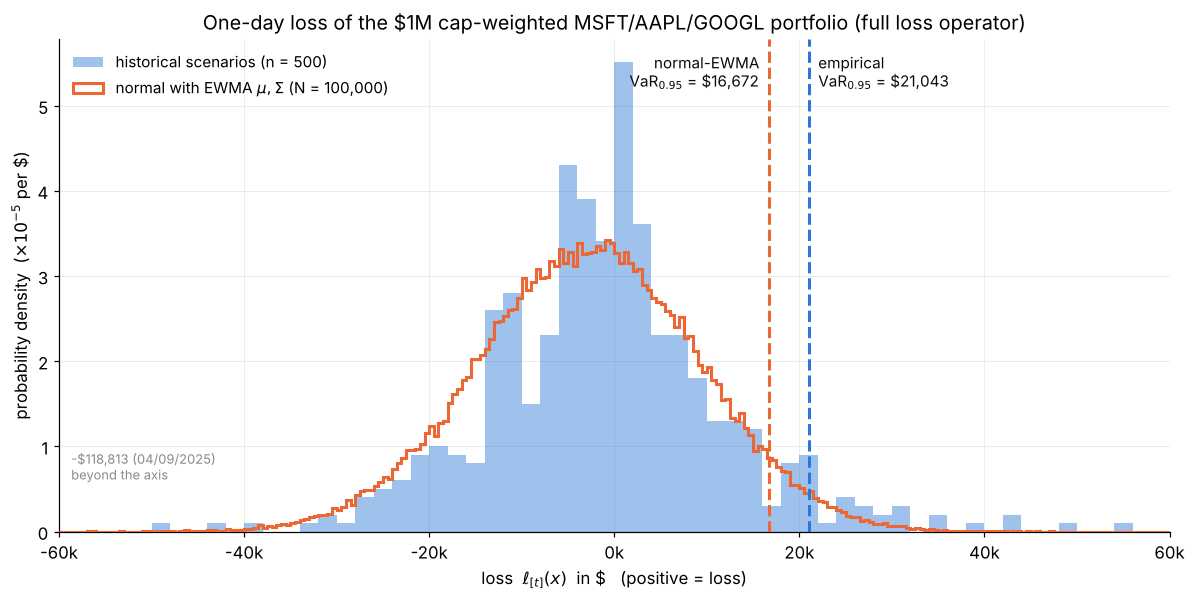

1 historical scenario(s) outside the plotted window: [-118813.]
saved var_est_loss_distributions.png


In [12]:
fig, ax = plt.subplots(figsize=(11, 5.6))
Lh, Ln = hist_losses["full"], mc_losses["full"]
lo, hi = -60_000, 60_000                                   # plotting window, $
bins_h = np.linspace(lo, hi, 61)
ax.hist(Lh, bins=bins_h, density=True, color=C_HIST, alpha=0.45, zorder=2,
        label=f"historical scenarios (n = {n_ret})")
ax.hist(Ln, bins=np.linspace(lo, hi, 241), density=True, histtype="step", color=C_NORM, lw=2.0,
        zorder=3, label=rf"normal with EWMA $\mu,\Sigma$ (N = {N_MC:,})")
ytop = ax.get_ylim()[1]
for v, c, lab, side in ((VAR_EMP["full"], C_HIST, "empirical", +1), (VAR_MC["full"], C_NORM, "normal-EWMA", -1)):
    ax.axvline(v, color=c, lw=2.0, ls="--", zorder=4)
    ax.annotate(f"{lab}\nVaR$_{{0.95}}$ = " + usd(v), xy=(v, ytop * 0.97), xytext=(6 * side, 0),
                textcoords="offset points", fontsize=10, color=C_INK, va="top",
                ha="left" if side > 0 else "right")
outside = Lh[(Lh < lo) | (Lh > hi)]
for o in outside:
    day = logret.index[int(np.flatnonzero(Lh == o)[0])].date()
    ax.annotate(f"{usd(o)} ({day:%m/%d/%Y})\nbeyond the axis", xy=(lo if o < lo else hi, ytop * 0.05),
                xytext=(8 if o < lo else -8, 18), textcoords="offset points", fontsize=8.5,
                color=C_MUTE, ha="left" if o < lo else "right")
ax.set_xlim(lo, hi)
ax.set_title(r"One-day loss of the \$1M cap-weighted MSFT/AAPL/GOOGL portfolio (full loss operator)")
ax.set_xlabel(r"loss  $\ell_{[t]}(x)$  in \$   (positive = loss)")
ax.set_ylabel(r"probability density  ($\times 10^{-5}$ per \$)")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v*1e5:.0f}"))
ax.legend(loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG1, bbox_inches="tight")
plt.show()
print(f"{len(outside)} historical scenario(s) outside the plotted window: {np.round(outside, 0)}")
print(f"saved {FIG1}")

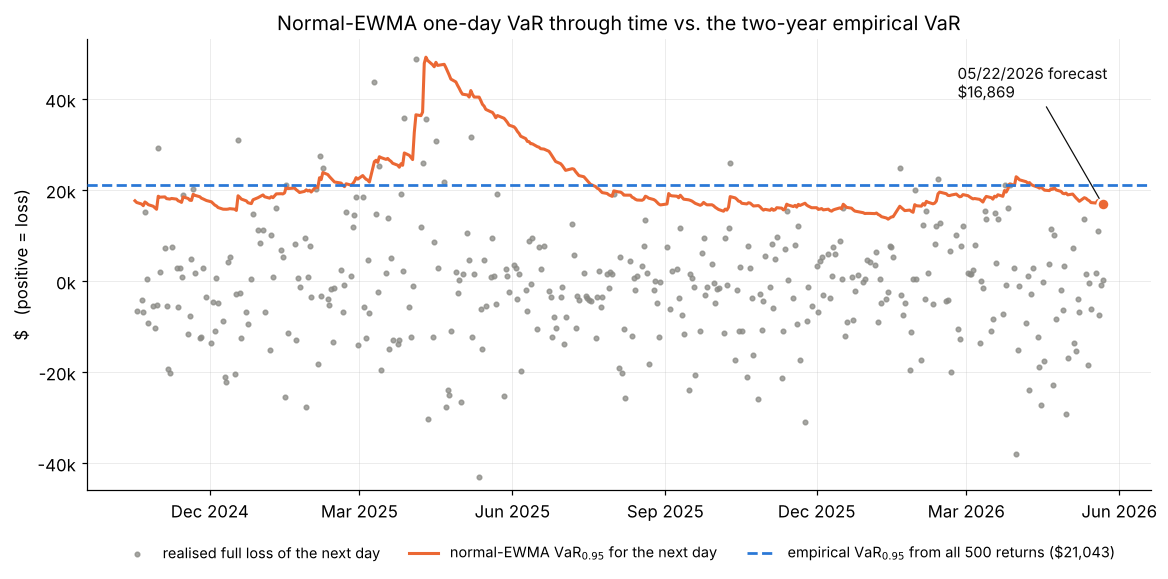

saved var_est_ewma_var_path.png   (first 100 EWMA updates treated as burn-in and not plotted; 2 realised gain(s) below -$46k not shown)
normal-EWMA VaR over the plotted window: median $18,625, min $13,614, max $49,216 on 2025-04-10
the 05/22/2026 value $16,869 is below 76% of the values on that path


In [13]:
BURN = 100
var_path = (-V_PORT * MU_PATH @ W
            + V_PORT * np.sqrt(np.einsum("i,kij,j->k", W, SIG_PATH, W)) * Z_ALPHA)
# var_path[k] is the forecast made after return k for return k+1
fdates = logret.index[BURN:]                          # date the forecast is made
vp = var_path[BURN:]
realised = hist_losses["full"][BURN + 1:]             # the loss it is forecasting

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.scatter(logret.index[BURN + 1:], realised, s=9, color=C_MUTE, alpha=0.75, zorder=2,
           label="realised full loss of the next day")
ax.plot(fdates, vp, color=C_NORM, lw=2.0, zorder=3, label="normal-EWMA VaR$_{0.95}$ for the next day")
ax.axhline(VAR_EMP["full"], color=C_HIST, lw=1.8, ls="--", zorder=3,
           label=f"empirical VaR$_{{0.95}}$ from all 500 returns ({usd(VAR_EMP['full'])})")
ax.scatter([fdates[-1]], [vp[-1]], s=60, color=C_NORM, edgecolor="white", lw=1.5, zorder=5)
ax.annotate("05/22/2026 forecast\n" + usd(vp[-1]), xy=(fdates[-1], vp[-1]), xytext=(-95, 70),
            textcoords="offset points", fontsize=10, color=C_INK,
            arrowprops=dict(arrowstyle="-", color=C_INK, lw=0.8))
ax.set_ylim(-46_000, 1.08 * vp.max())
n_clip = int((realised < -46_000).sum())
ax.set_title("Normal-EWMA one-day VaR through time vs. the two-year empirical VaR")
ax.set_ylabel(r"\$   (positive = loss)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=9.5)
fig.tight_layout()
fig.savefig(FIG2, bbox_inches="tight")
plt.show()
print(f"saved {FIG2}   (first {BURN} EWMA updates treated as burn-in and not plotted;"
      f" {n_clip} realised gain(s) below -$46k not shown)")
print(f"normal-EWMA VaR over the plotted window: median ${np.median(vp):,.0f}, "
      f"min ${vp.min():,.0f}, max ${vp.max():,.0f} on {fdates[int(np.argmax(vp))].date()}")
print(f"the 05/22/2026 value ${vp[-1]:,.0f} is below {100 * (vp > vp[-1]).mean():.0f}% of the values on that path")
assert abs(vp[-1] - VAR_LIN_EXACT) < 1e-6

---
## 12. All numbers for the written PDF

In [14]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"\n[DATA] {N_OBS} trading days {prices.index[0].date()} -> {prices.index[-1].date()}, "
      f"{n_ret} log returns")
print("\n[WEIGHTS]")
for t, w_, sh in zip(TICKERS, W, SHARES):
    print(f"  {t:<6} w = {w_:.6f}   ${V_PORT * w_:,.2f}   {sh:,.4f} shares")
print("\n[Q3 EMPIRICAL VaR_0.95]")
for nm, v in VAR_EMP.items():
    print(f"  {nm:<11} ${v:,.2f}")
print("\n[Q4 EWMA]")
print("  mu    =", np.array2string(MU_EW, formatter={"float_kind": lambda v: f"{v:.6e}"}))
print("  sd    =", np.array2string(vol, formatter={"float_kind": lambda v: f"{v:.6f}"}))
print("  Sigma =\n", np.array2string(SIG_EW, formatter={"float_kind": lambda v: f"{v: .6e}"}))
print("\n[Q5 NORMAL-EWMA VaR_0.95]")
print(f"  linearized (exact)   ${VAR_LIN_EXACT:,.2f}    m = {M_LIN:,.2f}, s = {S_LIN:,.2f}")
print(f"  full (MC)            ${VAR_MC['full']:,.2f}")
print(f"  quadratic (MC)       ${VAR_MC['quadratic']:,.2f}")
print(f"  linearized (MC)      ${VAR_MC['linearized']:,.2f}   (check)")
print("\n[Q6 DECOMPOSITION, linearized]")
print(f"  A {A:,.0f} -> B {B:,.0f} (shape {B - A:+,.0f}) -> C {Cc:,.0f} (covariance {Cc - B:+,.0f})"
      f" -> D {D:,.0f} (mean {D - Cc:+,.0f});  total {D - A:+,.0f}")

SUMMARY OF RESULTS

[DATA] 501 trading days 2024-05-23 -> 2026-05-22, 500 log returns

[WEIGHTS]
  MSFT   w = 0.253073   $253,072.85   604.6130 shares
  AAPL   w = 0.369231   $369,230.77   1,195.6180 shares
  GOOGL  w = 0.377696   $377,696.38   986.2297 shares

[Q3 EMPIRICAL VaR_0.95]
  full        $21,043.04
  linearized  $21,415.73
  quadratic   $21,038.61

[Q4 EWMA]
  mu    = [4.725682e-04 3.636476e-03 3.305902e-03]
  sd    = [0.017728 0.013881 0.021433]
  Sigma =
 [[ 3.142657e-04  3.431388e-05  3.463307e-06]
 [ 3.431388e-05  1.926842e-04  8.137581e-05]
 [ 3.463307e-06  8.137581e-05  4.593809e-04]]

[Q5 NORMAL-EWMA VaR_0.95]
  linearized (exact)   $16,869.11    m = -2,710.92, s = 11,903.81
  full (MC)            $16,671.73
  quadratic (MC)       $16,669.90
  linearized (MC)      $16,924.44   (check)

[Q6 DECOMPOSITION, linearized]
  A 21,416 -> B 21,792 (shape +376) -> C 18,621 (covariance -3,171) -> D 16,869 (mean -1,752);  total -4,547


---
## 13. Self-checks

In [15]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("501 trading days, 500 returns", N_OBS == 501 and n_ret == 500)
check("weights are cap shares and sum to one", np.allclose(W, CAP_TRN / CAP_TRN.sum()) and abs(W.sum() - 1) < 1e-12)
check("positions add up to V", abs(SHARES @ S_LAST - V_PORT) < 1e-6)
check("empirical VaR uses order statistic 475", emp_var(hist_losses["full"])[1] == 475)
check("MC VaR uses order statistic 95,000", emp_var(mc_losses["full"])[1] == 95_000)
check("full loss <= linearized loss in every historical scenario",
      np.all(hist_losses["full"] <= hist_losses["linearized"] + 1e-9))
check("full loss <= linearized loss in every simulated scenario",
      np.all(mc_losses["full"] <= mc_losses["linearized"] + 1e-9))
check("so VaR(full) <= VaR(linearized), both methods",
      VAR_EMP["full"] <= VAR_EMP["linearized"] and VAR_MC["full"] <= VAR_MC["linearized"])
check("quadratic within $50 of full, both methods",
      abs(VAR_EMP["quadratic"] - VAR_EMP["full"]) < 50 and abs(VAR_MC["quadratic"] - VAR_MC["full"]) < 50)
lo_, hi_ = quantile_band(mc_losses["linearized"])
check("exact linearized VaR inside the MC order-statistic band", lo_ <= VAR_LIN_EXACT <= hi_)
check("EWMA covariance is symmetric positive definite",
      np.allclose(SIG_EW, SIG_EW.T) and np.all(np.linalg.eigvalsh(SIG_EW) > 0))
mu2, sig2, _, _ = ewma_path(X_HIST[:, [1, 0, 2]])            # reorder the stocks
check("EWMA is equivariant to reordering the stocks",
      np.allclose(mu2, MU_EW[[1, 0, 2]]) and np.allclose(sig2, SIG_EW[np.ix_([1, 0, 2], [1, 0, 2])]))
# an independent loop-free EWMA as a cross-check of the recursion
k_ = np.arange(n_ret)[::-1]
mu_closed = (1 - LAM) * (LAM ** k_) @ X_HIST                  # closed form when mu_0 = 0
check("EWMA mean matches its closed form", np.allclose(mu_closed, MU_EW, rtol=1e-12, atol=1e-15))
check("decomposition adds up", abs((B - A) + (Cc - B) + (D - Cc) - (D - A)) < 1e-6)
check("figures written", FIG1.exists() and FIG2.exists())

w_ = max(len(nm) for nm, _ in checks)
for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  501 trading days, 500 returns
  [PASS]  weights are cap shares and sum to one
  [PASS]  positions add up to V
  [PASS]  empirical VaR uses order statistic 475
  [PASS]  MC VaR uses order statistic 95,000
  [PASS]  full loss <= linearized loss in every historical scenario
  [PASS]  full loss <= linearized loss in every simulated scenario
  [PASS]  so VaR(full) <= VaR(linearized), both methods
  [PASS]  quadratic within $50 of full, both methods
  [PASS]  exact linearized VaR inside the MC order-statistic band
  [PASS]  EWMA covariance is symmetric positive definite
  [PASS]  EWMA is equivariant to reordering the stocks
  [PASS]  EWMA mean matches its closed form
  [PASS]  decomposition adds up
  [PASS]  figures written

ALL CHECKS PASSED
